# 06 · Segmentos exploratorios: índice de equipamiento (MCA) y micro-mercados (K-means)

> **Análisis exploratorio.** Nada de este notebook alimenta la etapa 6 del pipeline, la lista oficial de avisos a
> investigar ni la regla de decisión. Responde si un índice de equipamiento y una segmentación de departamentos
> agregan algo frente a alternativas más simples. Si sirven, se propone cómo usarlos; no se incorporan.

**Propósito.** El plan de la materia sugería, para esta etapa, un índice sintético (PCA o MCA) y una segmentación en
micro-mercados (K-means). La consigna de la PreEntrega 3 no obliga a ninguna técnica y pide, para segmentos e
índices, **estabilidad, interpretación y utilidad**. Este notebook evalúa las tres cosas.

| Pregunta | Sección |
|---|---|
| ¿Se puede resumir el equipamiento del departamento en un índice confiable? | 2 |
| ¿Hay micro-mercados de departamentos, por sus características, que sean estables? | 3 |
| ¿Sirven para algo frente a la alternativa simple? (liquidez, precio esperado, primas, error) | 4 |
| Conclusión: sirve o no sirve, y para qué | 5 |
| Propuesta para el dashboard (no implementada) | 6 |

Las funciones están en `src/segmentos.py` (marcado como exploratorio; la etapa 6 no lo importa).

## 1. Configuración e ingesta

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src import segmentos
from src.configuracion import cargar_config
from src.eda import AZUL, AZUL_OSCURO, GRIS, ROJO

CFG = cargar_config()
SEMILLA = CFG["analisis"]["semilla"]
df = pd.read_csv(RAIZ / CFG["rutas"]["limpio"], sep="\t", low_memory=False)
etapa6 = pd.read_csv(RAIZ / CFG["rutas"]["precio_esperado"], sep="\t")
assert (df["id_aviso"].values == etapa6["id_aviso"].values).all()
df = df.join(etapa6[["zona", "unidad", "precio_m2_esperado", "brecha", "marcado", "estado_titulo", "tasa_completitud"]])
df["log_precio_m2"] = np.log(df["precio_m2_usd"])
# Segmento de barrio por precio, como en el notebook 04 (sección 7): la alternativa simple a la segmentación
df["tercil_barrio"] = pd.qcut(df.groupby("barrio")["precio_m2_usd"].transform("median"), 3,
                              labels=["barrios baratos", "medios", "caros"])
print(f"Avisos: {len(df):,}")

Avisos: 27,578


/var/folders/nv/tc0s6myn4sd_pdlkfbd7p2v40000gn/T/ipykernel_25238/1878939931.py:18: DtypeWarning: Columns (49) have mixed types. Specify dtype option on import or set low_memory=False.
  etapa6 = pd.read_csv(RAIZ / CFG["rutas"]["precio_esperado"], sep="\t")


## 2. Índice de equipamiento con MCA

**Qué resuelve.** El modelo de precio usa once amenities sueltas, y la ficha trae más. Un índice las resumiría en un
número ("qué tan equipado está el departamento o su edificio"), útil para describir, filtrar y, quizás, para el
modelo.

**Técnica, como en clase.** MCA (`prince`) sobre las características Sí/No como variables **activas**; el resto se
proyecta como **complementarias** (no arman los ejes).
- Activas, con las dos respuestas en la ficha (el vacío es falta de dato): aire acondicionado, ascensor, balcón,
  calefacción, conexión para lavarropas, dormitorio en suite, gas natural, lavandería, pileta, seguridad, terraza.
- Activas que la ficha publica solo cuando son "Sí" (el vacío no distingue "no tiene" de "no lo cargó"): gimnasio,
  parrilla, SUM, sauna, acceso a internet, agua corriente.
- Afuera: playroom, salón de fiestas y roof garden (menos del 2% de "Sí"; en el MCA las categorías raras inflan la
  inercia).
- Complementarias: precio por m², superficie, antigüedad, expensas por m², piso, brecha y completitud de la carga
  (numéricas); apto crédito, admite mascotas, estado según el título y tercil de precio del barrio (categóricas).

**Supuestos.** Las categorías describen bien al aviso, y la asociación entre ellas refleja un rasgo de fondo (el
equipamiento). Si el vacío no es "al azar", el MCA puede captar el patrón del vacío en lugar del equipamiento: es lo
primero que se revisa (2.1).

**Cómo se valida.** Se fija antes un criterio: el índice se sostiene si, en los avisos sin datos faltantes en las
columnas Sí/No, el índice calculado con todos y el calculado solo con esos avisos correlacionan al menos 0,9, y las
contribuciones de las categorías al eje también (2.3).

**Qué agrega frente a una alternativa simple.** Frente a contar los "Sí" o al índice de confort de la PreEntrega 2
(pesos puestos a mano), los pesos salen de los datos: pesan más las características que se presentan juntas. Si
mejora o no al modelo de precio se mide en la sección 4.

**Límites.** Con el vacío como "No" el índice confunde "no tiene" con "no lo cargó". Un eje del MCA describe
asociación entre categorías, no calidad ni valor: que se asocie con el precio hay que mostrarlo, no suponerlo.

### 2.1 El MCA ingenuo mide carga, no equipamiento

Primero, el MCA con el vacío como una categoría más ("sin dato" en las Sí/No, "no figura" en las solo Sí).

In [2]:
X_cat = segmentos.tabla_mca(df, "categoria")
mca_cat = segmentos.ajustar_mca(X_cat, semilla=SEMILLA)
F_cat = mca_cat.row_coordinates(X_cat)
print("Inercia explicada por los ejes 1 a 5 (%):", np.round(mca_cat.percentage_of_variance_[:5], 1))
pd.DataFrame({
    f"eje {k + 1}": {
        "correlación con la completitud de la carga": F_cat[k].corr(df["tasa_completitud"]),
        "correlación con el log del precio por m²": F_cat[k].corr(df["log_precio_m2"]),
    } for k in range(3)
}).round(2)

Inercia explicada por los ejes 1 a 5 (%): [22.1 13.3 10.   6.5  5.3]


,eje 1,eje 2,eje 3
correlación con la completitud de la carga,-0.94,-0.11,0.09
correlación con el log del precio por m²,-0.12,0.43,0.29


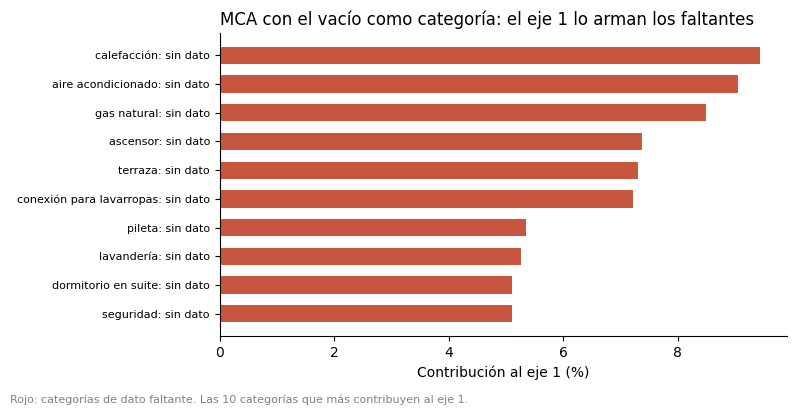

In [3]:
contrib_cat = segmentos.contribuciones_eje(mca_cat, 0).head(10)[::-1]
es_vacio = contrib_cat.index.str.contains("sin dato|no figura")
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(range(len(contrib_cat)), contrib_cat.values, color=[ROJO if v else GRIS for v in es_vacio], height=0.6)
ax.set_yticks(range(len(contrib_cat)), [segmentos.nombre_categoria(c) for c in contrib_cat.index],
              fontsize=8)
ax.set_xlabel("Contribución al eje 1 (%)")
ax.set_title("MCA con el vacío como categoría: el eje 1 lo arman los faltantes", loc="left")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.figtext(0.01, -0.02, "Rojo: categorías de dato faltante. Las 10 categorías que más contribuyen al eje 1.",
            fontsize=8, color="gray")
plt.tight_layout()
plt.show()

> **Interpretación:** el MCA ingenuo no mide equipamiento. Su eje 1 explica el 22,1% de la inercia, pero correlaciona −0,94 con la completitud de la carga, y las categorías que más lo arman son las de "sin dato" (en rojo). Ese eje separa los avisos cargados con cuidado de los cargados a medias, no los departamentos equipados de los que no lo están. Recién el eje 2 se asocia con el precio (0,43). Por eso el índice no puede salir de este MCA y se rehace tratando el vacío como "No" (2.2).

### 2.2 Índice con el vacío como "No"

El índice es la coordenada de cada aviso en el eje 1, con el signo fijado para que más alto signifique más "Sí".

In [4]:
X = segmentos.tabla_mca(df, "no")
mca = segmentos.ajustar_mca(X, semilla=SEMILLA)
df["indice_equipamiento"] = segmentos.indice_mca(mca, X)
cantidad_si = (X == "Sí").sum(axis=1)
print("Inercia explicada por los ejes 1 a 5 (%):", np.round(mca.percentage_of_variance_[:5], 1))
print(f"Correlación del índice con la cantidad de 'Sí': {df['indice_equipamiento'].corr(cantidad_si):.2f} | "
      f"con la completitud de la carga: {df['indice_equipamiento'].corr(df['tasa_completitud']):.2f} | "
      f"con el log del precio por m²: {df['indice_equipamiento'].corr(df['log_precio_m2']):.2f}")
segmentos.contribuciones_eje(mca, 0).head(10).round(1).rename(segmentos.nombre_categoria).to_frame("contribución al eje 1 (%)")

Inercia explicada por los ejes 1 a 5 (%): [23.  13.6  8.2  6.6  5.6]
Correlación del índice con la cantidad de 'Sí': 0.96 | con la completitud de la carga: 0.33 | con el log del precio por m²: 0.47


,contribución al eje 1 (%)
gimnasio: Sí,9.1
SUM: Sí,8.9
pileta: Sí,8.3
sauna: Sí,6.4
seguridad: Sí,6.1
parrilla: Sí,5.6
dormitorio en suite: Sí,4.9
aire acondicionado: Sí,4.4
acceso a internet: Sí,3.7
conexión para lavarropas: Sí,3.7


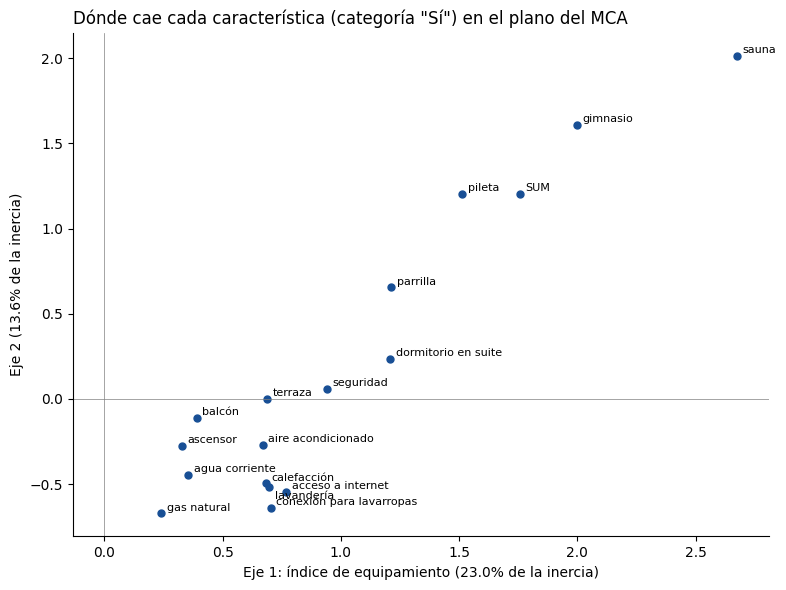

In [5]:
coord = mca.column_coordinates(X)
# Mismo signo que el índice (el signo de un eje del MCA es arbitrario)
signo = np.sign(df["indice_equipamiento"].corr(mca.row_coordinates(X)[0]))
si = coord[coord.index.str.endswith("__Sí")]
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(signo * si[0], si[1], color=AZUL_OSCURO, s=25)
desplazamiento = {"lavanderia__Sí": (4, -9)}   # para que no se pise con calefacción
for nombre, fila in si.iterrows():
    ax.annotate(segmentos.NOMBRES[nombre.replace("__Sí", "")], (signo * fila[0], fila[1]), fontsize=8,
                xytext=desplazamiento.get(nombre, (4, 2)), textcoords="offset points")
ax.axhline(0, color="gray", lw=0.5)
ax.axvline(0, color="gray", lw=0.5)
ax.set_xlabel(f"Eje 1: índice de equipamiento ({mca.percentage_of_variance_[0]:.1f}% de la inercia)")
ax.set_ylabel(f"Eje 2 ({mca.percentage_of_variance_[1]:.1f}% de la inercia)")
ax.set_title("Dónde cae cada característica (categoría \"Sí\") en el plano del MCA", loc="left")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

In [6]:
# Complementarias: las numéricas por su correlación con los ejes; las categóricas por el baricentro de sus
# avisos dividido por la raíz del autovalor (fórmula de transición, como en el notebook de clase)
F = pd.DataFrame({0: df["indice_equipamiento"], 1: mca.row_coordinates(X)[1]})
numericas = pd.DataFrame({
    "log precio por m²": df["log_precio_m2"], "log m²": np.log(df["m2_final"]), "antigüedad": df["antiguedad"],
    "log expensas por m²": np.log(df["expensas_usd"] / df["m2_final"]), "piso": df["numero_de_piso_de_la_unidad"],
    "brecha": df["brecha"], "completitud de la carga": df["tasa_completitud"],
})
print("Numéricas: correlación con los ejes")
display(pd.DataFrame({f"eje {k + 1}": numericas.corrwith(F[k]) for k in range(2)}).round(2))

raiz_lambda = np.sqrt(np.asarray(mca.eigenvalues_[:2], dtype=float))
categoricas = {"apto crédito": df["apto_credito"].fillna("sin dato"),
               "admite mascotas": df["admite_mascotas"].fillna("sin dato"),
               "estado según el título": df["estado_titulo"], "tercil de precio del barrio": df["tercil_barrio"]}
filas = []
for variable, valores in categoricas.items():
    baricentro = F.groupby(valores.values, observed=True).mean() / raiz_lambda
    for categoria, fila in baricentro.iterrows():
        filas.append({"variable": variable, "categoría": categoria, "avisos": int((valores == categoria).sum()),
                      "eje 1": fila[0], "eje 2": fila[1]})
print("Categóricas: coordenada (baricentro) en los ejes")
pd.DataFrame(filas).set_index(["variable", "categoría"]).round(2)

Numéricas: correlación con los ejes


,eje 1,eje 2
log precio por m²,0.47,0.29
log m²,0.24,-0.06
antigüedad,-0.34,-0.31
log expensas por m²,0.28,0.13
piso,0.03,0.01
brecha,0.05,0.08
completitud de la carga,0.33,-0.26


Categóricas: coordenada (baricentro) en los ejes


avisos  eje 1  eje 2
variable                    categoría                            
apto crédito                No                12878   0.06   0.10
                            Sí                11983   0.02  -0.20
                            sin dato           2717  -0.35   0.43
admite mascotas             No                13720  -0.23   0.17
                            Sí                 9898   0.44  -0.39
                            sin dato           3960  -0.31   0.39
estado según el título      a_estrenar          868   0.13   0.47
                            a_reciclar          141  -0.35  -0.30
                            a_refaccionar       111  -0.37  -0.26
                            sin_marca         25787   0.00  -0.00
                            ya_reformado        671  -0.15  -0.36
tercil de precio del barrio barrios baratos   10360  -0.25  -0.07
                            medios             8867  -0.03  -0.12
                            caros              8351   0.35   0.21

> **Interpretación:** con el vacío como "No", el eje 1 (23% de la inercia) pasa a ser equipamiento. Lo arman gimnasio, SUM, pileta, sauna y seguridad, las amenities típicas de los edificios con servicios. La correlación con la completitud baja de −0,94 a 0,33: queda algo, porque quien carga más campos tiende a marcar más "Sí". Las complementarias, que no participaron, cuadran con esa lectura: el índice sube con el precio por m² (0,47) y con las expensas (0,28), baja con la antigüedad (−0,34) y es más alto en los barrios caros (0,35) que en los baratos (−0,25).

### 2.3 ¿El índice se sostiene?

**Chequeo que define (avisos completos).** En los avisos que tienen dato en todas las columnas Sí/No, tratar el vacío
como "No" solo afecta a las columnas solo Sí. Se ajusta el MCA únicamente con esos avisos y se compara con el índice
ajustado con todos: si el eje 1 es el mismo rasgo, los dos índices tienen que correlacionar mucho en esos avisos, y
las categorías tienen que contribuir al eje en proporciones parecidas. Criterio fijado antes de mirar: las dos
correlaciones, de al menos 0,9.

**Chequeo complementario.** El eje 2 del MCA ingenuo (2.1), que ya no carga el patrón del vacío, comparado con el
índice.

In [7]:
completos = df[segmentos.COLUMNAS_SI_NO].notna().all(axis=1)
X_c = X[completos]
mca_c = segmentos.ajustar_mca(X_c, semilla=SEMILLA)
indice_c = segmentos.indice_mca(mca_c, X_c)
r_indices = df.loc[completos, "indice_equipamiento"].corr(indice_c)
contrib = pd.DataFrame({"todos los avisos": segmentos.contribuciones_eje(mca, 0),
                        "solo avisos completos": segmentos.contribuciones_eje(mca_c, 0)})
r_contrib = contrib.corr().iloc[0, 1]
sostiene = (abs(r_indices) >= 0.9) & (r_contrib >= 0.9)
print(f"Avisos completos: {completos.sum():,} ({100 * completos.mean():.0f}%)")
print(f"Correlación entre los dos índices, en los avisos completos: {r_indices:.2f}")
print(f"Correlación entre las contribuciones de las categorías al eje 1: {r_contrib:.2f}")
print(f"Criterio (las dos ≥ 0,9): {'SE SOSTIENE' if sostiene else 'NO SE SOSTIENE'}")
contrib.sort_values("todos los avisos", ascending=False).head(10).round(1).rename(index=segmentos.nombre_categoria)

Avisos completos: 14,909 (54%)


Correlación entre los dos índices, en los avisos completos: 0.99
Correlación entre las contribuciones de las categorías al eje 1: 0.93
Criterio (las dos ≥ 0,9): SE SOSTIENE


,todos los avisos,solo avisos completos
gimnasio: Sí,9.1,12.9
SUM: Sí,8.9,11.6
pileta: Sí,8.3,12.1
sauna: Sí,6.4,9.5
seguridad: Sí,6.1,4.6
parrilla: Sí,5.6,7.3
dormitorio en suite: Sí,4.9,5.5
aire acondicionado: Sí,4.4,2.7
acceso a internet: Sí,3.7,2.1
conexión para lavarropas: Sí,3.7,1.2


In [8]:
eje2_ingenuo = segmentos.indice_mca(mca_cat, X_cat, eje=1)
print(f"Correlación del índice con el eje 2 del MCA ingenuo: {df['indice_equipamiento'].corr(eje2_ingenuo):.2f} "
      f"(en los avisos completos: {df.loc[completos, 'indice_equipamiento'].corr(eje2_ingenuo[completos]):.2f})")

Correlación del índice con el eje 2 del MCA ingenuo: 0.88 (en los avisos completos: 1.00)


> **Interpretación:** el índice se sostiene con margen. En los 14.909 avisos completos, el índice ajustado con todos y el ajustado solo con los completos correlacionan 0,99, y las contribuciones de las categorías 0,93, las dos por encima del 0,9 fijado antes. Cambian algo los pesos (en los completos pesan más gimnasio, SUM y pileta, y menos aire acondicionado y conexión para lavarropas), pero las principales son las mismas. Además, el índice coincide con el eje 2 del MCA ingenuo (1,00 en los avisos completos): una vez que se saca el patrón del vacío, el equipamiento es el rasgo que sigue en los datos.

### 2.4 El índice casi coincide con contar amenities

El índice correlaciona casi 1 con la cantidad de "Sí" de las 17 características activas (2.2). O sea: el MCA da casi
lo mismo que contar. Lo único que agrega es el peso de cada característica: pesan más gimnasio, SUM, pileta y sauna,
que suelen venir juntas en los edificios con amenities.

Por eso, **en todas las comparaciones que siguen (K-means en la sección 3 y modelo de precio en la sección 4) el
conteo de amenities entra como alternativa simple**. Si funciona igual que el índice, la conclusión es que alcanza con
el conteo, que se explica en una línea ("cuántas de estas 17 características declara el aviso").

In [9]:
df["conteo_amenities"] = cantidad_si
print(f"Correlación índice y conteo: Pearson {df['indice_equipamiento'].corr(df['conteo_amenities']):.2f}, "
      f"Spearman {df['indice_equipamiento'].corr(df['conteo_amenities'], method='spearman'):.2f}")
# Cuánto varía el índice entre avisos con el mismo conteo: lo que el MCA agrega por los pesos
df.groupby("conteo_amenities")["indice_equipamiento"].describe()[["count", "min", "50%", "max"]].round(2)

Correlación índice y conteo: Pearson 0.96, Spearman 0.98


,count,min,50%,max
conteo_amenities,,,,
0,2792.0,-0.60,-0.60,-0.60
1,2308.0,-0.54,-0.49,-0.26
2,2221.0,-0.44,-0.38,-0.11
3,2900.0,-0.33,-0.28,0.23
4,3436.0,-0.23,-0.18,0.35
5,3167.0,-0.12,-0.05,0.63
6,2952.0,-0.00,0.08,0.75
7,2449.0,0.12,0.21,0.94
8,1855.0,0.23,0.33,1.04


## 3. Micro-mercados de departamentos con K-means

**Qué resuelve.** Agrupar los departamentos por sus características (no por su ubicación) en pocos tipos
reconocibles, para describir la oferta, filtrar en el dashboard y ver si el comportamiento (liquidez, error del
modelo, primas) cambia por tipo de departamento.

**Técnica, como en clase.** Variables winsorizadas en los percentiles 1 y 99 y estandarizadas (z-score), K-means++
con 20 arranques (`n_init`), K de 2 a 10 elegido por codo y silhouette, pero priorizando que los segmentos sean
accionables, y nombre de negocio para cada uno a partir de sus centroides en escala original.
- **Activas** (características del departamento): ambientes, log de m² por ambiente, antigüedad, log de expensas por
  m² e índice de equipamiento. No entra el log de m², porque correlaciona 0,83 con ambientes y el tamaño contaría
  dos veces; m² por ambiente casi no correlaciona con ambientes. No entra la ubicación ni el precio: la idea es
  segmentar tipos de departamento, no barrios caros o baratos (eso ya lo hacen los terciles del notebook 04).
- **Complementarias** (describen, no forman): piso (36% sin dato, imputarlo le metería un pico artificial al
  K-means), barrio y tercil de precio del barrio, precio por m², estado según el título, cochera, brecha y marca.
- **Faltantes:** antigüedad y expensas sin dato se completan con la mediana; el porcentaje se informa abajo.

**Supuestos.** K-means busca grupos compactos y de forma redonda, y con z-score todas las variables pesan lo mismo
en la distancia.

**Cómo se valida.** Estabilidad con ARI bootstrap (100 repeticiones con el 80% de los avisos y otra semilla; umbral
de clase: 0,8), silhouette (referencia de clase: más de 0,5) y tamaño de cada segmento entre repeticiones (alerta
si se mueve más de 5 puntos).

**Alternativas más simples.** Los terciles de precio del barrio (notebook 04, sección 7), las ambientes solas, y el
mismo K-means con el conteo de amenities en lugar del índice (3.4).

**Límites.** "El clustering propone, el experimento confirma": los segmentos describen, no prueban nada. Con una
silhouette baja, los segmentos son cortes de un continuo, no grupos naturales separados.

In [10]:
V, imputado = segmentos.variables_kmeans(df, df["indice_equipamiento"])
print("Sin dato, completado con la mediana (% de avisos):", (100 * imputado.mean()).round(1).to_dict())
V.corr().round(2)

Sin dato, completado con la mediana (% de avisos): {'ambientes': 0.0, 'log_m2_por_ambiente': 0.0, 'antiguedad': 2.8, 'log_expensas_m2': 17.0, 'indice_equipamiento': 0.0}


,ambientes,log_m2_por_ambiente,antiguedad,log_expensas_m2,indice_equipamiento
ambientes,1.00,0.03,0.34,-0.10,0.09
log_m2_por_ambiente,0.03,1.00,-0.17,0.09,0.31
antiguedad,0.34,-0.17,1.00,-0.17,-0.34
log_expensas_m2,-0.10,0.09,-0.17,1.00,0.25
indice_equipamiento,0.09,0.31,-0.34,0.25,1.00


### 3.1 Cuántos segmentos

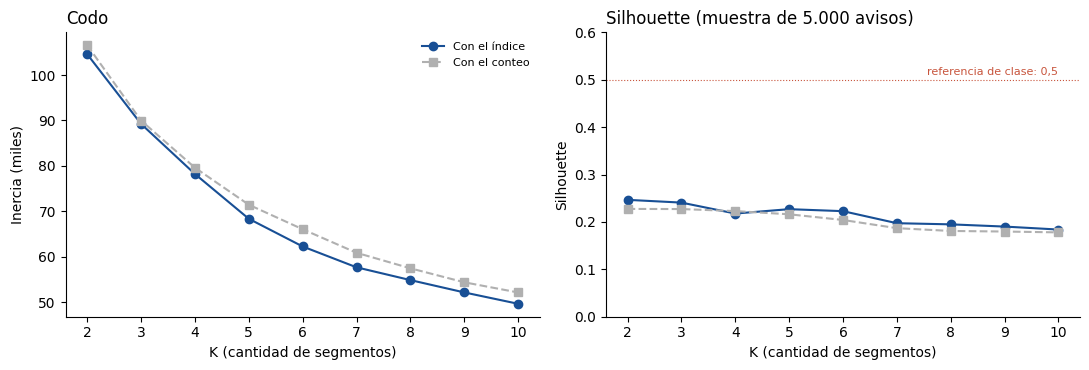

,inercia,silhouette,inercia_con_conteo,silhouette_con_conteo
k,,,,
2,104584.099,0.247,106549.292,0.227
3,89248.453,0.241,89985.431,0.227
4,78233.693,0.218,79616.874,0.223
5,68381.547,0.227,71468.720,0.216
6,62287.274,0.223,66077.156,0.204
7,57706.069,0.197,60900.556,0.187
8,54894.405,0.195,57486.395,0.181
9,52182.265,0.190,54411.499,0.180
10,49681.250,0.184,52173.480,0.178


In [11]:
Z, parametros = segmentos.escalar(V)
V_conteo, _ = segmentos.variables_kmeans(df, df["conteo_amenities"])
V_conteo = V_conteo.rename(columns={"indice_equipamiento": "conteo_amenities"})
Z_conteo, parametros_conteo = segmentos.escalar(V_conteo)
eleccion = pd.concat([segmentos.elegir_k(Z, semilla=SEMILLA),
                      segmentos.elegir_k(Z_conteo, semilla=SEMILLA).add_suffix("_con_conteo")], axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(eleccion.index, eleccion["inercia"] / 1000, marker="o", color=AZUL_OSCURO, label="Con el índice")
axes[0].plot(eleccion.index, eleccion["inercia_con_conteo"] / 1000, marker="s", ls="--", color=GRIS,
             label="Con el conteo")
axes[0].set_ylabel("Inercia (miles)")
axes[0].set_title("Codo", loc="left")
axes[1].plot(eleccion.index, eleccion["silhouette"], marker="o", color=AZUL_OSCURO, label="Con el índice")
axes[1].plot(eleccion.index, eleccion["silhouette_con_conteo"], marker="s", ls="--", color=GRIS,
             label="Con el conteo")
axes[1].set_ylim(0, 0.6)
axes[1].axhline(0.5, color=ROJO, lw=0.8, ls=":")
axes[1].text(10, 0.51, "referencia de clase: 0,5", ha="right", fontsize=8, color=ROJO)
axes[1].set_ylabel("Silhouette")
axes[1].set_title("Silhouette (muestra de 5.000 avisos)", loc="left")
for ax in axes:
    ax.set_xlabel("K (cantidad de segmentos)")
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()
eleccion.round(3)

### 3.2 Los segmentos con K = 4

**Elección de K.** No hay un codo claro y la silhouette es baja y parecida entre K = 2 y 6.
Se elige K = 4 porque da segmentos accionables y todos de más del 10% de los avisos; con K = 5 aparece un segmento
chico de expensas muy bajas, y con K = 2 o 3 se mezclan departamentos nuevos con y sin amenities. Los nombres salen
de una regla sobre los centroides (`segmentos.nombrar_segmentos`), no del número de etiqueta.

In [12]:
K = 4
km = segmentos.ajustar_kmeans(Z, K, semilla=SEMILLA)
centroides = segmentos.a_escala_original(pd.DataFrame(km.cluster_centers_, columns=V.columns), parametros)
nombres = segmentos.nombrar_segmentos(centroides)
df["segmento"] = pd.Series(km.labels_, index=df.index).map(nombres)
orden_segmentos = ["Chicos y recientes", "Compactos de edificio antiguo", "Nuevos con amenities",
                   "Familiares amplios y antiguos"]
tabla_segmentos = pd.DataFrame({
    "avisos": df["segmento"].value_counts(),
    "% de los avisos": 100 * df["segmento"].value_counts(normalize=True),
    "ambientes": centroides["ambientes"].rename(nombres),
    "m² por ambiente": np.exp(centroides["log_m2_por_ambiente"]).rename(nombres),
    "antigüedad (años)": centroides["antiguedad"].rename(nombres),
    "expensas (USD por m²)": np.exp(centroides["log_expensas_m2"]).rename(nombres),
    "índice de equipamiento": centroides["indice_equipamiento"].rename(nombres),
    "conteo de amenities (mediana)": df.groupby("segmento")["conteo_amenities"].median(),
}).loc[orden_segmentos]
tabla_segmentos.round(1)

,avisos,% de los avisos,ambientes,m² por ambiente,antigüedad (años),expensas (USD por m²),índice de equipamiento,conteo de amenities (mediana)
Chicos y recientes,7145,25.9,1.7,27.0,14.4,2.5,-0.1,4.0
Compactos de edificio antiguo,12167,44.1,2.8,19.5,48.0,1.9,-0.2,3.0
Nuevos con amenities,3446,12.5,2.7,29.3,12.2,3.5,0.9,10.0
Familiares amplios y antiguos,4820,17.5,4.3,31.6,51.9,2.3,0.0,6.0


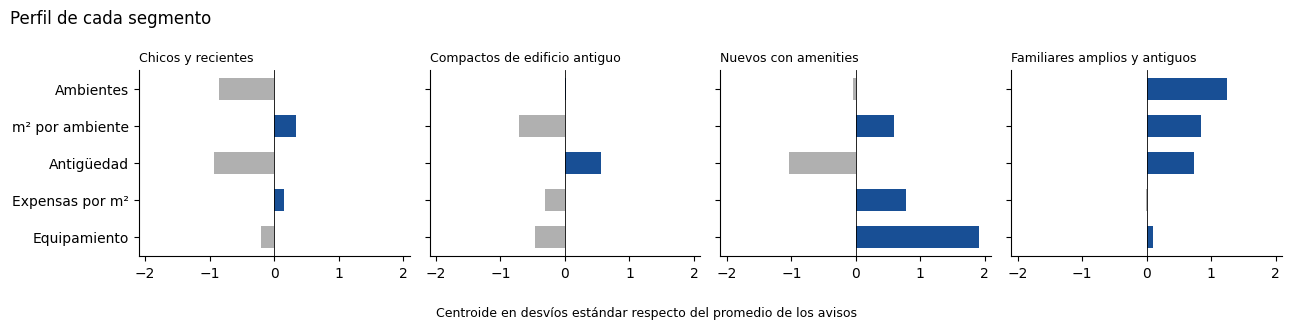

In [13]:
perfil = pd.DataFrame(km.cluster_centers_, columns=V.columns).rename(index=nombres).loc[orden_segmentos]
etiquetas_var = ["Ambientes", "m² por ambiente", "Antigüedad", "Expensas por m²", "Equipamiento"]
limite = np.ceil(10 * perfil.abs().max().max()) / 10 + 0.1
fig, axes = plt.subplots(1, K, figsize=(13, 3.2), sharey=True)
for ax, (nombre, fila) in zip(axes, perfil.iterrows()):
    ax.barh(range(len(fila)), fila.values, color=[AZUL_OSCURO if v > 0 else GRIS for v in fila.values], height=0.6)
    ax.axvline(0, color="black", lw=0.6)
    ax.set_title(nombre, loc="left", fontsize=9)
    ax.set_xlim(-limite, limite)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
axes[0].set_yticks(range(len(etiquetas_var)), etiquetas_var)
axes[0].invert_yaxis()
fig.supxlabel("Centroide en desvíos estándar respecto del promedio de los avisos", fontsize=9)
fig.suptitle("Perfil de cada segmento", x=0.01, ha="left")
plt.tight_layout()
plt.show()

In [14]:
# Complementarias: describen a cada segmento sin haber participado de su formación
descripcion = df.groupby("segmento").agg(
    precio_m2_mediano=("precio_m2_usd", "median"),
    piso_mediano=("numero_de_piso_de_la_unidad", "median"),
    con_cochera_pct=("cocheras", lambda c: 100 * (c.fillna(0) > 0).mean()),
    a_estrenar_pct=("estado_titulo", lambda e: 100 * (e == "a_estrenar").mean()),
    a_reciclar_o_refaccionar_pct=("estado_titulo", lambda e: 100 * e.isin(["a_reciclar", "a_refaccionar"]).mean()),
    marcados_pct=("marcado", lambda m: 100 * m.mean()),
    brecha_mediana_pct=("brecha", lambda b: 100 * b.median()),
).loc[orden_segmentos]
descripcion.round(1)

,precio_m2_mediano,piso_mediano,con_cochera_pct,a_estrenar_pct,a_reciclar_o_refaccionar_pct,marcados_pct,brecha_mediana_pct
segmento,,,,,,,
Chicos y recientes,2703.7,4.0,18.2,8.9,0.3,5.2,0.2
Compactos de edificio antiguo,2019.2,4.0,10.0,0.4,1.2,5.7,0.1
Nuevos con amenities,3715.4,5.0,56.2,4.6,0.0,6.5,1.2
Familiares amplios y antiguos,2350.8,4.0,46.5,0.6,1.8,11.1,-3.1


> **Interpretación:** los cuatro segmentos se pueden nombrar sin forzar. "Compactos de edificio antiguo" son casi la mitad de la oferta (44%): 2,8 ambientes chicos (19,5 m² cada uno), 48 años y las expensas más bajas. "Chicos y recientes" (26%) tienen 1,7 ambientes y 14 años; "Familiares amplios y antiguos" (17,5%), 4,3 ambientes y 52 años; y "Nuevos con amenities" (12,5%) son los únicos con índice alto (mediana de 10 amenities contra 3 a 6 en el resto) y expensas altas. Las complementarias cuadran: los nuevos con amenities tienen el precio por m² más alto (USD 3.715 contra 2.019 de los compactos) y más de la mitad tiene cochera.

Un dato que importa para la lista de avisos: en "Familiares amplios y antiguos" el modelo marca el 11,1% de los avisos, el doble que en los otros segmentos (5,2% a 6,5%), y la brecha mediana es −3,1% (en los demás, entre 0 y +1,2%). O sea, el precio esperado tiende a quedar alto en ese tipo de departamento, y parte de sus señales puede venir de ese sesgo y no de un precio realmente bajo.

### 3.3 Estabilidad

In [15]:
aris, tamanos, original = segmentos.estabilidad_kmeans(Z, K, repeticiones=100, semilla=SEMILLA)
assert (original == km.labels_).all()
tamano_original = 100 * np.bincount(km.labels_, minlength=K) / len(Z)
desvio_max = (tamanos - tamano_original).abs().max()
estabilidad = pd.DataFrame({
    "tamaño (%)": tamano_original,
    "tamaño mínimo en el bootstrap (%)": tamanos.min(),
    "tamaño máximo en el bootstrap (%)": tamanos.max(),
    "desvío máximo (pp)": desvio_max,
}).rename(index=nombres).loc[orden_segmentos]
sil = eleccion.loc[K, "silhouette"]
print(f"ARI bootstrap: mediana {aris.median():.3f}, percentil 10 {aris.quantile(0.1):.3f}, mínimo {aris.min():.3f} "
      f"({'supera' if aris.quantile(0.1) >= 0.8 else 'no supera'} el umbral de clase de 0,8)")
print(f"Silhouette: {sil:.2f} ({'supera' if sil > 0.5 else 'por debajo de'} la referencia de clase de 0,5)")
print(f"Tamaños: desvío máximo {desvio_max.max():.1f} pp ({'dentro' if desvio_max.max() <= 5 else 'fuera'} "
      f"de la alerta de ±5 pp)")
estabilidad.round(1)

ARI bootstrap: mediana 0.991, percentil 10 0.986, mínimo 0.975 (supera el umbral de clase de 0,8)
Silhouette: 0.22 (por debajo de la referencia de clase de 0,5)
Tamaños: desvío máximo 0.4 pp (dentro de la alerta de ±5 pp)


,tamaño (%),tamaño mínimo en el bootstrap (%),tamaño máximo en el bootstrap (%),desvío máximo (pp)
Chicos y recientes,25.9,25.6,26.3,0.4
Compactos de edificio antiguo,44.1,43.8,44.4,0.4
Nuevos con amenities,12.5,12.1,12.7,0.4
Familiares amplios y antiguos,17.5,17.2,17.7,0.3


> **Interpretación:** los segmentos son estables. En 100 remuestreos el ARI mediano es 0,99 (mínimo 0,975, muy por encima del 0,8 de clase) y ningún segmento cambia de tamaño más de 0,4 pp. Pero la silhouette es 0,22, lejos del 0,5 de referencia: los avisos no forman grupos separados, sino un continuo que K-means corta siempre en el mismo lugar. Hay que leerlos como cortes útiles y reproducibles, no como tipos naturales de departamento.

### 3.4 ¿Se pisa con los terciles de precio del barrio?

Los segmentos se armaron sin la ubicación. Si igual coincidieran con los terciles de barrio, serían otra forma de
decir "barrio caro o barato". Se mide con la distribución de cada segmento por tercil y con el ARI entre las dos
particiones (0 = independientes, 1 = iguales).

In [16]:
from sklearn.metrics import adjusted_rand_score

cruce = pd.crosstab(df["segmento"], df["tercil_barrio"], normalize="index").mul(100).loc[orden_segmentos]
print(f"ARI entre segmentos y terciles de barrio: {adjusted_rand_score(df['segmento'], df['tercil_barrio']):.3f}")
print("% de los avisos de cada segmento en cada tercil (el total de la ciudad, en la última fila):")
pd.concat([cruce, df["tercil_barrio"].value_counts(normalize=True).mul(100).to_frame("Total").T]).round(1)

ARI entre segmentos y terciles de barrio: 0.045
% de los avisos de cada segmento en cada tercil (el total de la ciudad, en la última fila):


tercil_barrio,barrios baratos,medios,caros
Chicos y recientes,32.9,32.3,34.8
Compactos de edificio antiguo,50.1,28.9,21.1
Nuevos con amenities,18.3,25.3,56.4
Familiares amplios y antiguos,26.8,45.1,28.1
Total,37.6,32.2,30.3


> **Interpretación:** no se pisan. El ARI con los terciles de barrio es 0,045, casi independencia. Hay inclinaciones esperables: los "Nuevos con amenities" están 56% en barrios caros (30% en toda la ciudad) y los "Compactos de edificio antiguo", 50% en barrios baratos (38% en la ciudad), mientras que "Chicos y recientes" se reparte casi parejo. Pero en cada tercil hay de todos los tipos: el segmento agrega una mirada que la ubicación sola no da.

### 3.5 ¿Y con el conteo de amenities en lugar del índice?

El mismo K-means, con el conteo en lugar del índice (alternativa simple, 2.4). Si los segmentos salen parecidos y
igual de estables, el índice no agrega nada a la segmentación. Como la regla de nombres de 3.2 no separa los segmentos que salen
con el conteo, se muestran con una etiqueta que resume su centroide.

In [17]:
km_conteo = segmentos.ajustar_kmeans(Z_conteo, K, semilla=SEMILLA)
centroides_conteo = segmentos.a_escala_original(pd.DataFrame(km_conteo.cluster_centers_, columns=V_conteo.columns),
                                                parametros_conteo)
# La regla de nombres de 3.2 no separa estos segmentos (el de más ambientes es también el de más amenities):
# cada uno se muestra con una etiqueta que resume su centroide
etiqueta_conteo = {s: f"{f['ambientes']:.1f} amb., {f['antiguedad']:.0f} años, conteo {f['conteo_amenities']:.1f}"
                   for s, f in centroides_conteo.sort_values("ambientes").iterrows()}
df["segmento_conteo"] = pd.Series(km_conteo.labels_, index=df.index).map(etiqueta_conteo)
print("Segmentos con el conteo:")
display(pd.DataFrame({
    "% de los avisos": 100 * df["segmento_conteo"].value_counts(normalize=True),
    "m² por ambiente": np.exp(centroides_conteo["log_m2_por_ambiente"]).rename(etiqueta_conteo),
    "expensas (USD por m²)": np.exp(centroides_conteo["log_expensas_m2"]).rename(etiqueta_conteo),
}).loc[list(etiqueta_conteo.values())].round(1))
aris_conteo, tamanos_conteo, _ = segmentos.estabilidad_kmeans(Z_conteo, K, repeticiones=100, semilla=SEMILLA)
pd.DataFrame({
    "con el índice": {"silhouette": eleccion.loc[K, "silhouette"], "ARI bootstrap (percentil 10)": aris.quantile(0.1)},
    "con el conteo": {"silhouette": eleccion.loc[K, "silhouette_con_conteo"],
                      "ARI bootstrap (percentil 10)": aris_conteo.quantile(0.1)},
}).round(3)

Segmentos con el conteo:


,% de los avisos,m² por ambiente,expensas (USD por m²)
"1.8 amb., 11 años, conteo 5.8",30.5,27.2,2.8
"2.7 amb., 48 años, conteo 3.2",41.6,19.9,2.4
"3.1 amb., 45 años, conteo 3.4",9.7,23.0,0.7
"4.3 amb., 42 años, conteo 7.2",18.2,32.6,2.7


,con el índice,con el conteo
silhouette,0.218,0.223
ARI bootstrap (percentil 10),0.986,0.975


In [18]:
print(f"ARI entre la segmentación con el índice y con el conteo: "
      f"{adjusted_rand_score(df['segmento'], df['segmento_conteo']):.3f}")
print("% de los avisos de cada segmento (con el índice) según su segmento con el conteo:")
pd.crosstab(df["segmento"], df["segmento_conteo"], normalize="index").mul(100).loc[
    orden_segmentos, list(etiqueta_conteo.values())].round(1)

ARI entre la segmentación con el índice y con el conteo: 0.546
% de los avisos de cada segmento (con el índice) según su segmento con el conteo:


segmento_conteo,"1.8 amb., 11 años, conteo 5.8","2.7 amb., 48 años, conteo 3.2","3.1 amb., 45 años, conteo 3.4","4.3 amb., 42 años, conteo 7.2"
segmento,,,,
Chicos y recientes,83.7,12.0,4.0,0.3
Compactos de edificio antiguo,0.6,82.0,15.8,1.6
Nuevos con amenities,68.0,0.3,0.2,31.5
Familiares amplios y antiguos,0.0,13.4,9.3,77.2


**Resultado.** En la segmentación, el índice sí aporta frente al conteo: con el índice aparece el segmento
"Nuevos con amenities" (edificios nuevos con gimnasio, SUM, pileta), que con el conteo se diluye entre los
departamentos chicos y recientes y los familiares. La diferencia sale de los pesos del MCA: contar trata igual a
un gimnasio que a una conexión para lavarropas.

> **Interpretación:** con el conteo, la segmentación es igual de estable y de separada (silhouette 0,223 contra 0,218), pero divide otra cosa: el ARI entre las dos es 0,55. El 68% de los "Nuevos con amenities" cae, con el conteo, en el grupo de departamentos chicos y recientes, y aparece un grupo de expensas casi nulas (0,7 USD por m², 9,7% de los avisos) difícil de interpretar. Para segmentar, los pesos del MCA importan: distinguir un gimnasio de una conexión para lavarropas es lo que hace aparecer el segmento de edificios con amenities.

## 4. ¿Sirven para algo? Utilidad frente a la alternativa simple

Tres preguntas, en orden de prioridad:
1. **Liquidez (4.1):** ¿la tasa de salida del portal cambia por segmento, más allá de lo que ya dicen las ambientes?
   Es lo que alimentaría el componente de liquidez de la regla de decisión.
2. **Modelo de precio (4.2):** ¿el índice de equipamiento mejora el precio esperado frente a las amenities sueltas y
   frente al conteo?
3. **Primas y error por segmento (4.3):** descriptivo, con intervalos de confianza.

### 4.1 Liquidez: tasa de salida del portal por segmento

**Dato.** En el segundo relevamiento (27 y 28/10/2026) se registró qué avisos del primero ya no estaban. Se excluyen
los barrios truncados por el tope de 2.016 resultados del primer relevamiento (Palermo, Belgrano, Caballito y
Recoleta). Salir del portal no es lo mismo que venderse: puede ser venta, retiro o una republicación no detectada.

**Alternativa simple.** Las ambientes, que es lo que usa hoy `config/costos.yaml` para el tiempo de venta.

**Comparación.** Logit fuera de muestra con 5 vueltas agrupadas por unidad, y pérdida logarítmica por aviso (más baja
= mejor predicción). La diferencia contra el modelo con solo ambientes lleva un IC 95% remuestreando unidades; si
es negativa y el IC no incluye el 0, el segmento agrega información. Entra también el segmento armado con el conteo
(3.5).

In [19]:
from src import modelo

seguimiento = pd.read_csv(RAIZ / "data/processed/seguimiento_avisos.csv")
assert (seguimiento["id_aviso"].values == df["id_aviso"].values).all()
df["salio"] = seguimiento["salio"].astype(int)
df["ambientes_grupo"] = df["ambientes"].fillna(df["dormitorios"] + 1).clip(1, 6).astype(int).map(
    lambda a: f"{a} amb." if a < 5 else "5 amb. o más")
liquidez = df[~seguimiento["barrio_truncado"]].copy()
unidad_liq = modelo.grupo_de_unidad(liquidez).values
print(f"Avisos fuera de los barrios truncados: {len(liquidez):,} | salieron del portal: "
      f"{100 * liquidez['salio'].mean():.1f}%")


def tasa_por_grupo(grupo):
    filas = {}
    for nombre in grupo.dropna().unique():
        sel = (grupo == nombre).values
        tasa, inf, sup = segmentos.bootstrap_estadistico(liquidez["salio"].values[sel], unidad_liq[sel], b=500,
                                                         semilla=SEMILLA)
        filas[nombre] = {"avisos": int(sel.sum()), "tasa_salida_%": 100 * tasa, "ic_inf_%": 100 * inf,
                         "ic_sup_%": 100 * sup}
    return pd.DataFrame(filas).T


tasa_segmento = tasa_por_grupo(liquidez["segmento"]).loc[orden_segmentos]
tasa_ambientes = tasa_por_grupo(liquidez["ambientes_grupo"]).sort_index()
display(tasa_segmento.round(1))
tasa_ambientes.round(1)

Avisos fuera de los barrios truncados: 19,579 | salieron del portal: 40.2%


,avisos,tasa_salida_%,ic_inf_%,ic_sup_%
Chicos y recientes,5478.0,40.1,38.7,41.5
Compactos de edificio antiguo,9281.0,42.9,41.9,44.0
Nuevos con amenities,2378.0,34.9,32.7,36.9
Familiares amplios y antiguos,2442.0,35.4,33.2,37.4


,avisos,tasa_salida_%,ic_inf_%,ic_sup_%
1 amb.,3240.0,41.4,39.5,43.3
2 amb.,5669.0,43.0,41.6,44.4
3 amb.,6320.0,39.8,38.6,41.3
4 amb.,3339.0,37.8,36.1,39.5
5 amb. o más,1011.0,31.2,27.9,34.5


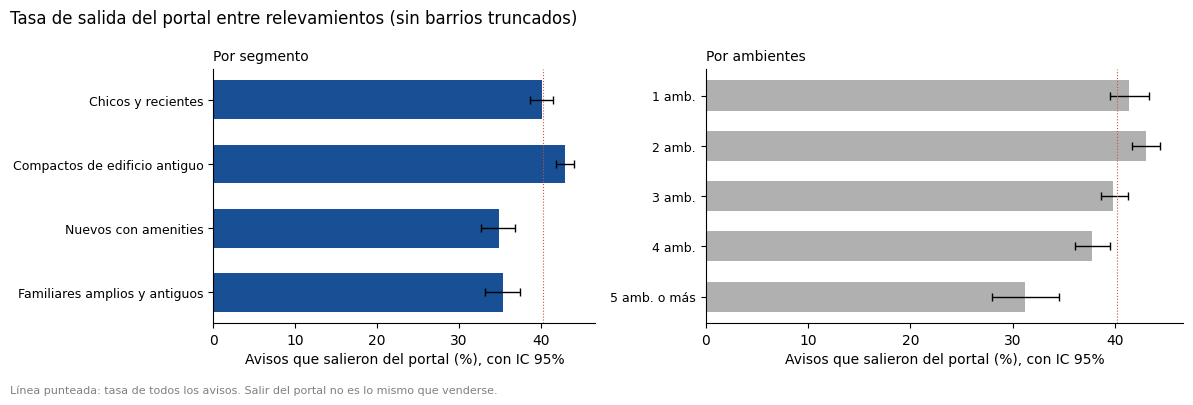

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [4, 5]}, sharex=True)
for ax, tabla, titulo in [(axes[0], tasa_segmento, "Por segmento"), (axes[1], tasa_ambientes, "Por ambientes")]:
    pos = np.arange(len(tabla))[::-1]
    ax.barh(pos, tabla["tasa_salida_%"], color=AZUL_OSCURO if titulo == "Por segmento" else GRIS, height=0.6)
    ax.errorbar(tabla["tasa_salida_%"], pos, xerr=[tabla["tasa_salida_%"] - tabla["ic_inf_%"],
                                                   tabla["ic_sup_%"] - tabla["tasa_salida_%"]],
                fmt="none", color="black", lw=1, capsize=3)
    ax.axvline(100 * liquidez["salio"].mean(), color=ROJO, lw=0.8, ls=":")
    ax.set_yticks(pos, tabla.index, fontsize=9)
    ax.set_title(titulo, loc="left", fontsize=10)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.set_xlabel("Avisos que salieron del portal (%), con IC 95%")
fig.suptitle("Tasa de salida del portal entre relevamientos (sin barrios truncados)", x=0.01, ha="left")
plt.figtext(0.01, -0.03, "Línea punteada: tasa de todos los avisos. Salir del portal no es lo mismo que venderse.",
            fontsize=8, color="gray")
plt.tight_layout()
plt.show()

In [21]:
explicativas = {
    "solo la tasa promedio": liquidez.iloc[:, :0],
    "ambientes (alternativa simple)": pd.get_dummies(liquidez["ambientes_grupo"], drop_first=True, dtype=float),
    "segmento": pd.get_dummies(liquidez["segmento"], drop_first=True, dtype=float),
    "segmento armado con el conteo": pd.get_dummies(liquidez["segmento_conteo"], drop_first=True, dtype=float),
}
explicativas["ambientes + segmento"] = pd.concat([explicativas["ambientes (alternativa simple)"],
                                                  explicativas["segmento"]], axis=1)
perdida = {nombre: segmentos.log_loss_por_aviso(
               liquidez["salio"], segmentos.probabilidad_fuera_de_muestra(liquidez["salio"], X_, unidad_liq,
                                                                           semilla=SEMILLA))
           for nombre, X_ in explicativas.items()}
filas = {}
for nombre, valores in perdida.items():
    dif, inf, sup = segmentos.bootstrap_estadistico(valores - perdida["ambientes (alternativa simple)"], unidad_liq,
                                                    b=500, semilla=SEMILLA)
    filas[nombre] = {"pérdida logarítmica media": valores.mean(), "diferencia contra ambientes": dif,
                     "ic_inf": inf, "ic_sup": sup,
                     "mejora sobre la tasa promedio (%)": 100 * (1 - valores.mean() /
                                                                 perdida["solo la tasa promedio"].mean())}
pd.DataFrame(filas).T.round(5)

,pérdida logarítmica media,diferencia contra ambientes,ic_inf,ic_sup,mejora sobre la tasa promedio (%)
solo la tasa promedio,0.67385,0.00128,0.00049,0.00216,0.00000
ambientes (alternativa simple),0.67258,0.00000,0.00000,0.00000,0.18954
segmento,0.67198,-0.00060,-0.00157,0.00048,0.27837
segmento armado con el conteo,0.67132,-0.00126,-0.00239,-0.00002,0.37648
ambientes + segmento,0.67115,-0.00143,-0.00222,-0.00052,0.40124


> **Interpretación:** la tasa de salida cambia por segmento: 42,9% en los compactos de edificio antiguo contra 34,9% en los nuevos con amenities, con intervalos que no se superponen. Pero las ambientes cuentan algo parecido (de 43,0% en 2 ambientes a 31,2% en 5 o más). Como predictor, el segmento solo no le gana a las ambientes (el IC de la diferencia incluye el 0). El segmento armado con el conteo y la combinación de ambientes y segmento sí le ganan, pero todas las variantes mejoran menos de 0,5% sobre predecir la tasa promedio: con lo que hay en el aviso se explica muy poco de quién sale del portal, que depende de cosas que no vemos (urgencia del vendedor, negociación, republicaciones). Para el componente de liquidez de la regla alcanza con las ambientes.

### 4.2 Modelo de precio: índice, conteo o amenities sueltas

El lineal ampliado de la etapa 6, con las mismas cinco vueltas sin fuga, cambiando solo cómo entra el equipamiento:
- **amenities oficiales:** el modelo de hoy (las amenities sueltas que ya usa);
- **17 sueltas:** las 17 características activas del MCA, cada una como variable;
- **conteo:** cuántas de esas 17 declara el aviso (alternativa simple);
- **índice MCA:** el índice de equipamiento, con el MCA ajustado **solo con los avisos de entrenamiento** de cada
  vuelta (si se ajustara con todos, los avisos de prueba influirían en el índice que los evalúa).

Para que sea comparable con la etapa 6, acá los avisos con geocodificación dudosa y los barrios con sub-zonas
inestables se tratan igual que ahí. El primer
chequeo es que la variante oficial reproduzca el precio esperado de la etapa 6. La métrica es el error mediano fuera
de muestra, y la diferencia entre variantes lleva un IC 95% remuestreando unidades (positiva = la variante tiene más
error que la de referencia).

In [22]:
from src import analisis, validacion

df_modelo = analisis.tratar_geo_dudoso(analisis.unir_fuentes_externas(
    pd.read_csv(RAIZ / CFG["rutas"]["limpio"], sep="\t", low_memory=False), CFG["rutas"]), CFG["enriquecimiento"])
y_modelo = np.log(df_modelo["precio_m2_usd"])
# Como en la etapa 6: los barrios con sub-zonas inestables (ARI bajo el mínimo) se comparan enteros
estabilidad_modelo = validacion.estabilidad_subzonas(df_modelo, repeticiones=CFG["analisis"]["repeticiones_estabilidad"])
inestables = list(estabilidad_modelo.index[estabilidad_modelo["ari_mediano"] < CFG["analisis"]["ari_minimo_subzona"]])
print(f"Barrios con sub-zona inestable (comparados enteros): {inestables or 'ninguno'}")
pred_equipamiento = segmentos.precio_esperado_con_equipamiento(
    df_modelo, y_modelo, CFG["analisis"]["k_folds"], SEMILLA, CFG["analisis"]["minimo_grupo"], CFG["analisis"]["iqr_k"],
    barrios_excluidos=inestables)
assert np.allclose(np.exp(pred_equipamiento["amenities_oficiales"]), etapa6["precio_m2_esperado"]), \
    "la variante oficial no reproduce la etapa 6"
print("La variante oficial reproduce el precio esperado de la etapa 6.")
validacion.metricas(y_modelo, pred_equipamiento, CFG["analisis"]["umbral"]).round(2)

/Users/gonzalobuhler/Documents/Facultad (ITBA)/2026 - 2C/Descriptiva/tp1-fondo-inmobiliario/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Definiendo sub-zonas por clustering...


  Sub-zonas creadas: 197 en total.


Barrios con sub-zona inestable (comparados enteros): ['villa-santa-rita']


La variante oficial reproduce el precio esperado de la etapa 6.


,error_mediano_%,error_p75_%,dentro_de_10%_%,marcados
amenities_oficiales,12.51,21.91,41.15,1819.0
sueltas_17,12.44,21.84,41.26,1791.0
conteo,12.85,22.25,40.36,1937.0
indice_mca,12.70,22.16,40.53,1884.0


In [23]:
unidad_modelo = modelo.grupo_de_unidad(df_modelo)
comparaciones = [("17 sueltas", "sueltas_17", "amenities_oficiales"),
                 ("conteo", "conteo", "amenities_oficiales"),
                 ("índice MCA", "indice_mca", "amenities_oficiales"),
                 ("índice MCA contra conteo", "indice_mca", "conteo")]
pd.DataFrame({
    nombre: dict(zip(["diferencia de error mediano (pp)", "ic_inf_pp", "ic_sup_pp"],
                     validacion.bootstrap_diferencia_error(y_modelo, pred_equipamiento[a], pred_equipamiento[b],
                                                           unidad_modelo, b=500)))
    for nombre, a, b in comparaciones
}).T.round(3)

,diferencia de error mediano (pp),ic_inf_pp,ic_sup_pp
17 sueltas,-0.069,-0.154,0.003
conteo,0.335,0.198,0.425
índice MCA,0.185,0.086,0.264
índice MCA contra conteo,-0.150,-0.206,-0.076


> **Interpretación:** el índice no mejora el precio esperado. Con él, el error mediano sube 0,19 pp frente a las amenities del modelo oficial (IC 0,09 a 0,26), y con el conteo, 0,34 pp. Las 17 características sueltas dan prácticamente lo mismo que el modelo oficial (−0,07 pp, el IC toca el 0). Tiene sentido: al resumir el equipamiento en un número se pierde que cada característica se paga distinto (en el notebook 04, el balcón suma y el ascensor no), y el modelo lineal ya las pondera por separado. El modelo oficial queda como está.

### 4.3 Primas y error del modelo por segmento (descriptivo)

**Error.** El error mediano del precio esperado oficial (etapa 6, fuera de muestra) en cada segmento, con IC 95%
remuestreando unidades, junto al de cada tercil de precio del barrio (la alternativa simple).

**Primas.** El lineal ampliado ajustado dentro de cada segmento, con la zona de la etapa 6 y sin atípicos; IC 95%
remuestreando unidades. Como en el notebook 04 (sección 6), son asociaciones dentro de la zona, no efectos causales.

In [24]:
error_abs = df["brecha"].abs()
unidad_df = modelo.grupo_de_unidad(df).values
filas = []
for tipo, grupo in [("segmento", df["segmento"]), ("tercil de barrio", df["tercil_barrio"].astype(str))]:
    for nombre in grupo.unique():
        sel = (grupo == nombre).values
        med, inf, sup = segmentos.bootstrap_estadistico(error_abs.values[sel], unidad_df[sel], np.median, b=300,
                                                        semilla=SEMILLA)
        filas.append({"agrupación": tipo, "grupo": nombre, "avisos": int(sel.sum()), "error_mediano_%": 100 * med,
                      "ic_inf_%": 100 * inf, "ic_sup_%": 100 * sup})
print(f"Error mediano de todos los avisos: {100 * error_abs.median():.1f}%")
pd.DataFrame(filas).set_index(["agrupación", "grupo"]).round(1)

Error mediano de todos los avisos: 12.5%


avisos  error_mediano_%  \
agrupación       grupo                                                    
segmento         Familiares amplios y antiguos    4820             14.3   
                 Compactos de edificio antiguo   12167             11.9   
                 Nuevos con amenities             3446             13.4   
                 Chicos y recientes               7145             11.9   
tercil de barrio caros                            8351             12.4   
                 medios                           8867             12.6   
                 barrios baratos                 10360             12.5   

                                                ic_inf_%  ic_sup_%  
agrupación       grupo                                              
segmento         Familiares amplios y antiguos      13.9      14.7  
                 Compactos de edificio antiguo      11.7      12.2  
                 Nuevos con amenities               12.8      14.0  
                 Chicos y recientes                 11.5      12.2  
tercil de barrio caros                              12.1      12.7  
                 medios                             12.3      12.9  
                 barrios baratos                    12.3      12.9

In [25]:
from src.limpieza import outliers_iqr_por_grupo

zona = etapa6["zona"]
y = np.log(df["precio_m2_usd"])
Xa = validacion.caracteristicas_ampliadas(df_modelo)
log_exp = np.log(df_modelo["expensas_usd"] / df_modelo["m2_final"])
Xa = Xa.assign(expensas_rel_zona=(log_exp - log_exp.groupby(zona).transform("median")).fillna(0),
               expensas_sin_dato=log_exp.isna().astype(float))
usar = ~outliers_iqr_por_grupo(y, zona, k=CFG["analisis"]["iqr_k"], minimo_grupo=CFG["analisis"]["minimo_grupo"])
clave = ["cochera", "balcon", "terraza", "pileta", "ascensor", "dormitorio_en_suite"]
unidad_serie = pd.Series(unidad_df, index=df.index)
primas_segmento = {}
for nombre in orden_segmentos:
    sel = df["segmento"] == nombre
    A = modelo.matriz_diseno(Xa[sel], zona[sel])
    primas_segmento[nombre] = validacion.bootstrap_primas(y[sel], A, usar[sel], unidad_serie[sel], clave, b=200)
pd.concat(primas_segmento, axis=1).round(1)

Chicos y recientes                    \
                               prima_% ic_inf_% ic_sup_%   
cochera                           13.5     11.9     15.0   
balcon                             2.0      1.1      3.1   
terraza                            2.2      1.0      3.7   
pileta                             3.4      2.0      4.9   
ascensor                          -1.9     -3.0     -1.1   
dormitorio_en_suite                5.1      3.3      7.1   

                    Compactos de edificio antiguo                    \
                                          prima_% ic_inf_% ic_sup_%   
cochera                                      16.5     15.3     17.8   
balcon                                        7.6      6.8      8.4   
terraza                                       3.0      1.9      4.3   
pileta                                        6.7      2.5     11.3   
ascensor                                      0.0     -0.7      0.6   
dormitorio_en_suite                           3.0      0.8      5.5   

                    Nuevos con amenities                    \
                                 prima_% ic_inf_% ic_sup_%   
cochera                             10.7      8.7     12.7   
balcon                               1.9     -0.3      4.0   
terraza                              0.3     -1.3      1.6   
pileta                               2.9      1.1      4.7   
ascensor                            -1.4     -3.7      0.5   
dormitorio_en_suite                  2.4      1.0      4.1   

                    Familiares amplios y antiguos                    
                                          prima_% ic_inf_% ic_sup_%  
cochera                                      16.7     14.8     18.3  
balcon                                       -0.1     -1.8      1.4  
terraza                                       1.3     -1.0      3.4  
pileta                                        9.0      4.2     14.9  
ascensor                                     -0.7     -1.9      0.8  
dormitorio_en_suite                           7.4      5.7      9.3

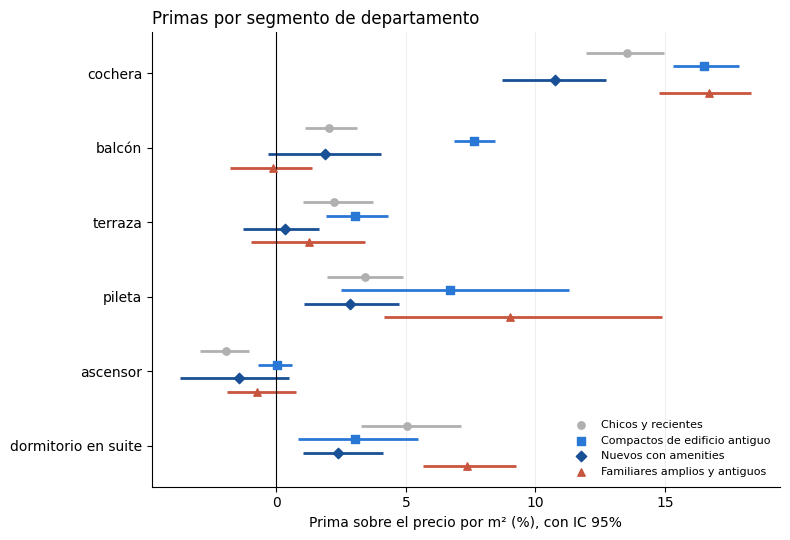

In [26]:
fig, ax = plt.subplots(figsize=(8, 5.5))
colores_seg = dict(zip(orden_segmentos, [GRIS, AZUL, AZUL_OSCURO, ROJO]))
marcadores = dict(zip(orden_segmentos, ["o", "s", "D", "^"]))
for j, nombre in enumerate(orden_segmentos):
    tabla = primas_segmento[nombre]
    ys = np.arange(len(clave)) + (j - 1.5) * 0.18
    ax.hlines(ys, tabla["ic_inf_%"], tabla["ic_sup_%"], color=colores_seg[nombre], lw=2)
    ax.scatter(tabla["prima_%"], ys, color=colores_seg[nombre], marker=marcadores[nombre], s=28, zorder=3,
               label=nombre)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(range(len(clave)), [segmentos.NOMBRES.get(c, c.replace("_", " ")) for c in clave])
ax.invert_yaxis()
ax.set_xlabel("Prima sobre el precio por m² (%), con IC 95%")
ax.set_title("Primas por segmento de departamento", loc="left")
ax.legend(frameon=False, fontsize=8, loc="lower right")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.grid(axis="x", color="#eeeeee")
plt.tight_layout()
plt.show()

> **Interpretación:** el modelo es menos preciso en dos segmentos: "Familiares amplios y antiguos" (14,3%, IC 13,9 a 14,7) y "Nuevos con amenities" (13,4%), contra 11,9% en los otros dos. Entre terciles de barrio el error casi no cambia (12,4% a 12,6%), así que el segmento dice algo que el barrio no. En los familiares se suma el sesgo visto en 3.2: más error y precio esperado tirado para arriba, por eso conviene mirar sus señales con más cuidado.

En las primas hay diferencias: la cochera se paga en todos los segmentos (11% a 17%), el balcón pesa sobre todo en los compactos de edificio antiguo (7,6%, contra 2% o menos en el resto) y el dormitorio en suite más en los familiares (7,4%). La pileta tiene intervalos muy anchos. Es heterogeneidad real, pero no alcanza para justificar un modelo por segmento.

## 5. Conclusión: ¿sirve o no sirve, y para qué?

Los números son los de las secciones 2 a 4 (corrida del 5/11/2026). Patrón descriptivo y relación estadística, no
recomendación de inversión: nada de esto cambia la lista oficial ni la regla de decisión.

**Índice de equipamiento (MCA).**
- **Es confiable** como medida: se sostiene en los avisos completos (correlación 0,99 entre los dos índices) y no
  mide la carga del aviso, a diferencia del MCA ingenuo (−0,94 con la completitud).
- **Sirve para segmentar y describir:** con el índice aparece el segmento "Nuevos con amenities", que con el conteo
  se diluye.
- **No sirve para el modelo de precio:** con el índice, el error mediano sube 0,19 pp (IC 0,09 a 0,26) frente a las
  amenities sueltas de hoy; con el conteo, 0,34 pp. Las 17 características sueltas no cambian el error (−0,07 pp,
  IC −0,15 a 0,00). El índice le gana al conteo (−0,15 pp), pero ninguno conviene: el modelo oficial queda como está.

**Segmentos de departamento (K-means, K = 4).**
- **Son estables** (ARI bootstrap 0,99, tamaños que se mueven menos de 0,5 pp) pero **no están separados**
  (silhouette 0,22): son cortes útiles de un continuo, no grupos naturales.
- **No se pisan con los terciles de barrio** (ARI 0,045): agregan una mirada que la ubicación no da.
- **Sirven para la incertidumbre:** el error del modelo es mayor en "Familiares amplios y antiguos" (14,3%) y en
  "Nuevos con amenities" (13,4%) que en los otros dos (11,9%); entre terciles de barrio casi no cambia (12,4% a
  12,6%). Es una señal concreta para el analista: en esos dos tipos la brecha es menos precisa.
- **Y para una alerta de sesgo:** en "Familiares amplios y antiguos" el modelo marca el 11,1% de los avisos, el
  doble que en el resto (5,2% a 6,5%), y la brecha mediana es −3,1% (en los demás, entre 0 y +1,2%): el precio
  esperado tiende a quedar alto en ese tipo de departamento, así que parte de sus señales puede ser sesgo del
  modelo y no un precio realmente bajo. Conviene mirarlas con más cuidado.
- **Para la liquidez, describen bien pero predicen poco:** la tasa de salida va de 34,9% ("Nuevos con amenities") a
  42,9% ("Compactos de edificio antiguo"), con intervalos que no se superponen. Pero como predictor, el segmento solo
  no le gana a las ambientes (IC de la diferencia incluye el 0), y sumarlo a las ambientes mejora la pérdida
  logarítmica en una fracción mínima. **Para el componente de liquidez de la regla alcanza con las ambientes**, que
  además son más fáciles de explicar.
- **Primas:** la cochera se paga en todos los segmentos (11% a 17%); el balcón pesa sobre todo en los compactos
  de edificio antiguo (7,6%, contra 2% o menos en el resto) y el dormitorio en suite más en los familiares (7,4%). Es heterogeneidad real, pero con
  intervalos anchos en pileta; no justifica un modelo por segmento.

**En una línea:** el índice y los segmentos **sirven para describir la oferta, filtrar y marcar dónde el precio
esperado es menos preciso; no sirven para mejorar el precio esperado ni para reemplazar a las ambientes en la
liquidez.** Frente a la alternativa simple: en el modelo de precio ganan las amenities sueltas; en la liquidez,
las ambientes alcanzan; en la segmentación, el índice le gana al conteo.

**Límites.** Salir del portal no es venderse. K = 4 es una elección entre varias razonables (la silhouette es
pareja entre 2 y 6). El índice trata el vacío como "No". Los segmentos describen; "el clustering propone, el
experimento confirma".

## 6. Qué se llevó el dashboard (implementado el 05/11/2026)

Siempre como información descriptiva, nunca como puntaje del ranking:
1. **Segmento de cada aviso:** `src/exportar_dashboard.py` repite esta segmentación (mismo MCA, mismo K-means, misma
   semilla) y guarda el segmento en `docs/dashboard/data/avisos.json`. La etapa 6 no cambia: el segmento no entra a
   la lista oficial ni a la regla.
2. **Alerta de precisión en "Familiares amplios y antiguos":** en la ficha y en el buscador, con el mismo estilo que
   las otras alertas de revisión: "tipo de departamento con más error del modelo (14,3% contra 12,5% de la ciudad):
   el precio esperado tiende a quedar alto". No excluye a nadie de ninguna lista (un test lo verifica).
3. Quedan sin implementar el filtro por tipo de departamento y la tasa de salida por segmento en la ficha: para la
   liquidez alcanza con las ambientes (sección 4.1).